# Implementation of a transformer model
In this exercise we will implement the transformer model (an architecture based on LLama2). The squeleton of the code is provided and you should complete it (mostly self attention mechanism).

In [17]:
import math
import os
import sys
import time
from pathlib import Path

import torch
from torch import nn, optim
from torch.nn import functional as F
from torch.utils.data import DataLoader
from datasets import load_dataset
from transformers import AutoTokenizer

# Support both the repository root and the Part1 directory as notebook cwd.
PART1_DIR = next((p.resolve() for p in (
    Path.cwd(), Path.cwd() / "Part1",
    Path.cwd() / "Lab5_LM_Transformers" / "Part1"
) if (p / "rope_embedding.py").exists()), None)
if PART1_DIR is None:
    raise RuntimeError("Open the notebook from Part1, Lab5_LM_Transformers, or the repository root")
sys.path.insert(0, str(PART1_DIR))
from rope_embedding import RoPE
from experiment import train_run, plot_run, timestamp
import json
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
# Avoid excessive CPU thread overhead for this small model.
torch.set_num_threads(min(4, os.cpu_count() or 1))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 4 if device.type == "cuda" else 2
MAX_LENGTH = 128 if device.type == "cuda" else 64
# MAX_STEPS caps total optimizer updates across NUM_EPOCHS passes.
MAX_STEPS = 1000 if device.type == "cuda" else 500
TRAIN_EXAMPLES = 2000
VALIDATION_EXAMPLES = 32
NUM_EPOCHS = 1
EVAL_EVERY = 50
RUNS_DIR = PART1_DIR / "runs"
print(f"Device: {device}; batch size: {BATCH_SIZE}; maximum steps: {MAX_STEPS}")


Device: cpu; batch size: 2; maximum steps: 500


## Self Attention with no mask

Let consider $Q, K, V \in R^{B\times H \times L \times N}$ for each batch element (B) for each heads (H) we want to compute $$A = \frac{Q_{bh}.K_{bh}^{t}}{\sqrt{N}}$$

Attention weights are defined by $$ 
softmax(A_i) = \begin{pmatrix}
\frac{e^{A_{i1}}}{\sum\limits_{j=1}^L  e^{A_{ij}}} & 
\frac{e^{A_{i2}}}{\sum\limits_{j=1}^L  e^{A_{ij}}} & 
\dots &
\frac{e^{A_{iL}}}{\sum\limits_{j=1}^L  e^{A_{ij}}}
\end{pmatrix}$$ 
And $$ 
Softmax(A) = \begin{pmatrix}
\frac{e^{A_{11}}}{\sum\limits_{j=1}^L  e^{A_{1j}}} & 
\frac{e^{A_{12}}}{\sum\limits_{j=1}^L  e^{A_{1j}}} & 
\dots &
\frac{e^{A_{1L}}}{\sum\limits_{j=1}^L  e^{A_{1j}}} \\
\frac{e^{A_{21}}}{\sum\limits_{j=1}^L  e^{A_{2j}}} & 
\frac{e^{A_{22}}}{\sum\limits_{j=1}^L  e^{A_{2j}}} & 
\dots &
\frac{e^{A_{2l}}}{\sum\limits_{j=1}^L  e^{A_{2j}}} \\
\vdots & \vdots & \ddots & \vdots \\
\frac{e^{A_{L1}}}{\sum\limits_{j=1}^L  e^{A_{Lj}}} & 
\frac{e^{A_{L2}}}{\sum\limits_{j=1}^L  e^{A_{Lj}}} & 
\dots &
\frac{e^{A_{LL}}}{\sum\limits_{j=1}^L  e^{A_{Lj}}}
\end{pmatrix}$$ 


Notice that the function softmax can be used to compute this matrix [`torch.softmax`](https://docs.pytorch.org/docs/stable/generated/torch.softmax.html#torch.softmax).


## Masked Attention
In many cases, certains tokens will not compute attention with later tokens (padding or decoding approaches). Typically in decoder only architectures we would have the attention weights matrix only considering lower diagonal values :

$$ 
Softmax(A) = \begin{pmatrix}
\frac{e^{A_{11}}}{\sum\limits_{j=1}^1  e^{A_{1j}}} & 
0 & 
\dots & 0 &
0 \\
\frac{e^{A_{21}}}{\sum\limits_{j=1}^2  e^{A_{2j}}} & 
\frac{e^{A_{22}}}{\sum\limits_{j=1}^2  e^{A_{2j}}} & 
\dots & 0 &
0 \\
\vdots & \vdots & \ddots & \vdots \\
\frac{e^{A_{{L-1}1}}}{\sum\limits_{j=1}^{L-1}  e^{A_{L-1j}}} & 
\frac{e^{A_{{L-1}2}}}{\sum\limits_{j=1}^{L-1}  e^{A_{L-1j}}} & 
\dots &
\frac{e^{A_{L-1L-1}}}{\sum\limits_{j=1}^{L-1}  e^{A_{L-1j}}}& 0 \\
\frac{e^{A_{L1}}}{\sum\limits_{j=1}^L  e^{A_{Lj}}} & 
\frac{e^{A_{L2}}}{\sum\limits_{j=1}^L  e^{A_{Lj}}} & 
\dots &
\frac{e^{A_{LL-1}}}{\sum\limits_{j=1}^L  e^{A_{Lj}}} & 
\frac{e^{A_{LL}}}{\sum\limits_{j=1}^L  e^{A_{Lj}}} \\
\end{pmatrix}$$ 

A simple implementation would consist in setting the upper diagonal of A to $-\infty$ and apply the softmax. We will thus consider a matrix name $M$ (or `mask` in the code) having upper diagonal element to $-\infty$ : 
$$ M = 
\begin{pmatrix}
0& 
-\infty & 
\dots & -\infty&
-\infty \\
0 & 
0 & 
\dots & -\infty &
-\infty \\
\vdots & \vdots & \ddots & \vdots \\
0 & 
0 & 
\dots &
0& -\infty \\
0 & 
0 & 
\dots &
0 & 
0\\
\end{pmatrix}
$$

And apply softmax on $A + M$

In [18]:
def multi_head_attention(q, k, v, mask=None):
    """Q: [B,H,Q,D], K/V: [B,H,K,D]; additive mask: [B,Q,K]."""
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])
    if mask is not None:
        if mask.ndim == 3:
            mask = mask.unsqueeze(1)
        scores = scores + mask.to(device=q.device, dtype=q.dtype)
    attention_weights = torch.softmax(scores, dim=-1)
    # Fully masked padding queries contribute zero rather than NaN.
    attention_weights = torch.nan_to_num(attention_weights, nan=0.0)
    return attention_weights, attention_weights @ v


In [19]:
q = k = v = torch.ones(1, 1, 3, 4)
mask = torch.triu(torch.full((1, 3, 3), -torch.inf), diagonal=1)
attention_weights, attention_output = multi_head_attention(q, k, v, mask)
torch.testing.assert_close(attention_weights, torch.tensor(
    [[[[1., 0., 0.], [1/2, 1/2, 0.], [1/3, 1/3, 1/3]]]]))
torch.testing.assert_close(attention_output, v)
print("Masked attention check passed")


Masked attention check passed


##  Create the attention module

In pytorch module are block of neural networks that inherit from the class `nn.Module`.  In the following you willbe asked to complete the attention code. The attention module compute the Query $Q$, the Keys $K$ and Values $V$ for each heads and compute attention. The forward methods is the method implementing these operations. In this lab we use a mult-head attention, meaning that we compute attention for each heads, that can be done with a for loop or using batched operation (it is up to you). Also as we follow the Llama 2 architecture, we use for positional embeding the RoPe positonal encoding that is applied on the two matrix $Q$ and $K$. The forward function should compute for an input $X \in \mathbb{R}^{L \times N}$ (in the decoder only case) the following:

1. $Q_h = RoPE(W^q_{h}X^{\intercal})$ (for all heads h) with $W^q_h \in \mathbb{R}^{N \times N}$
2. $K_h = RoPE(W^k_{h}X^{\intercal})$ (for all heads h)
3. $V_h = W^v_{h}X^{\intercal}$ (for all heads h)
4. $A_h =  Attention(Q_h, K_h, V_h)$ (for all heads h)
5. $A$ = [A_1, A_2, \dots A_H] (the concatenation along the last dimension)
6. $O = W^oA^{\intercal}$ with $w^{o} \in \mathbb{R}^{N \times NH}$ (NH being the scalar multplication of N and H)

Notice that Q, K and V can be computed without a loop using $W_{q}$ (respectively for $W_k$ and $W_v$) .


In [20]:
class RoPEAttentionModule(nn.Module):
    def __init__(self, input_dim, output_dim, num_heads=1):
        super().__init__()
        # output_dim is the dimension of ONE head.
        self.Wq, self.Wk, self.Wv = (
            nn.Linear(input_dim, output_dim * num_heads) for _ in range(3))
        self.output_dim = output_dim
        self.num_heads = num_heads
        self.Wo = nn.Linear(output_dim * num_heads, input_dim)
        self.rope_func = RoPE(output_dim)

    def forward(self, x, attention_mask=None, y=None, decoder_mask=True,
                k_cache=None, v_cache=None, start_cache=0):
        query_input = x if y is None else y
        batch, query_len, _ = query_input.shape
        key_len = x.shape[1]

        def split_heads(tensor, length):
            return tensor.reshape(batch, length, self.num_heads,
                                  self.output_dim).transpose(1, 2)

        q = self.rope_func(split_heads(self.Wq(query_input), query_len), start_cache)
        k = self.rope_func(split_heads(self.Wk(x), key_len), start_cache)
        v = split_heads(self.Wv(x), key_len)
        if (k_cache is None) != (v_cache is None):
            raise ValueError("Provide both key and value caches")
        if k_cache is not None:
            if y is not None:
                raise ValueError("Caching is supported for self-attention only")
            end = start_cache + key_len
            if end > k_cache.shape[2]:
                raise ValueError("KV cache capacity exceeded")
            k_cache[:, :, start_cache:end] = k
            v_cache[:, :, start_cache:end] = v
            k, v = k_cache[:, :, :end], v_cache[:, :, :end]
        total_keys = k.shape[2]
        mask = q.new_zeros(batch, query_len, total_keys)
        if decoder_mask:
            query_positions = start_cache + torch.arange(query_len, device=x.device)
            key_positions = torch.arange(total_keys, device=x.device)
            mask.masked_fill_(key_positions[None, :] > query_positions[:, None], -torch.inf)
        if attention_mask is not None:
            # Hugging Face convention: 1/True is a real token, 0/False is padding.
            if attention_mask.shape != (batch, total_keys):
                raise ValueError("attention_mask must cover all keys, including cached keys")
            mask.masked_fill_(~attention_mask.to(device=x.device, dtype=torch.bool)[:, None, :],
                              -torch.inf)
        attention_weights, output = multi_head_attention(q, k, v, mask)
        output = output.transpose(1, 2).contiguous().reshape(
            batch, query_len, self.num_heads * self.output_dim)
        return attention_weights, self.Wo(output)


## Trasnsformer FeedForward

The FeedForward Network is defined using Llama 2 architecture as following for $X \in \mathbb{R^{L\times N}}$ :


1. $G = SiLU(W^gX^\intercal)$ with $W^g \in \mathbb{R}^{M \times N}$ (see SiLU in pytorch [documentation](https://docs.pytorch.org/docs/stable/generated/torch.nn.SiLU.html))
2. $U = W^u X^\intercal$ with $W^u  \in \mathbb{R}^{M \times N}$
3. $I = G \odot U$ (Hadamard multiplication)
4. $O = W^{o} I^{\intercal}$ with $W_{o} \in \mathbb{R}^{N \times M}$






In [21]:
class TransformerFeedForward(nn.Module):
    def __init__(self, embed_size, intermediate_size):
        super().__init__()
        self.gate_proj = nn.Linear(embed_size, intermediate_size)
        self.up_proj = nn.Linear(embed_size, intermediate_size)
        self.down_proj = nn.Linear(intermediate_size, embed_size)
        self.gate_func = nn.SiLU()

    def forward(self, x):
        return self.down_proj(self.gate_func(self.gate_proj(x)) * self.up_proj(x))


## Transformer block
We can now create the block of the 

Let consider $x_0 \in \mathbb{R}^{B \times L \times N}$, the decoder block is given by : 

* $x_1 = LN_1(x_0)$ (apply layer norm)
* $x_2 = Attention(x_1)$ (apply attention)
* $x_3 = x_0 + x_2$ (adding residual)
* $x_4 = LN_2(x_3)$
* $y = FF(x_4) + x_3$


In [22]:
class TransformerDecoderBlock(nn.Module):
    def __init__(self, embed_size, intermediate_size, num_heads):
        super().__init__()
        if embed_size % num_heads or (embed_size // num_heads) % 2:
            raise ValueError("Embedding size must divide into even-sized attention heads")
        self.attention_module = RoPEAttentionModule(
            embed_size, embed_size // num_heads, num_heads=num_heads)
        self.feed_forward = TransformerFeedForward(embed_size, intermediate_size)
        self.attention_layer_norm = nn.RMSNorm(embed_size)
        self.feed_forward_layer_norm = nn.RMSNorm(embed_size)

    def forward(self, x, attention_mask=None, k_cache=None, v_cache=None,
                start_cache=0, layer=0):
        _, attention_output = self.attention_module(
            self.attention_layer_norm(x), attention_mask=attention_mask,
            k_cache=k_cache, v_cache=v_cache, start_cache=start_cache)
        x = x + attention_output
        return x + self.feed_forward(self.feed_forward_layer_norm(x))


## The Model

The model contain a stack of block on input embedding, it applies the different transformation and should return both the output embeddings and the logits (size of the vocabulary).

It should return $o_{e} \mathbb{R}^{B\times L \times N}$ and $\hat{y}\in \mathbb{R}^{B\times L \times V}$ with : 

* $o_e = RMSNORM \left( b_h\circ \dots   \circ \circ b_2 \circ b_1 (w_{word\_embedding}x^\intercal) \right)$ with $b_i$ the $i^{th}$ block
* $\hat{y} = W_{lm\_head} o_e^{T}$



In [23]:
class TransformerDecoder(nn.Module):
    def __init__(self, vocabulary_size, embed_size, intermediate_size,
                 num_heads, hidden_layers=5, **kwargs):
        super().__init__(**kwargs)
        self.nh, self.nhl, self.es = num_heads, hidden_layers, embed_size
        self.wte = nn.Embedding(vocabulary_size, embed_size)
        self.blocks = nn.ModuleList([
            TransformerDecoderBlock(embed_size, intermediate_size, num_heads)
            for _ in range(hidden_layers)])
        self.ln_f = nn.RMSNorm(embed_size)
        self.lm_head = nn.Linear(embed_size, vocabulary_size)

    def forward(self, input_ids, attention_mask=None, k_cache=None,
                v_cache=None, start_cache=0):
        intermediate = self.wte(input_ids)
        for i, block in enumerate(self.blocks):
            intermediate = block(
                intermediate, attention_mask=attention_mask,
                k_cache=None if k_cache is None else k_cache[i],
                v_cache=None if v_cache is None else v_cache[i],
                start_cache=start_cache, layer=i)
        output_embed = self.ln_f(intermediate)
        return output_embed, self.lm_head(output_embed)


##  Training the transformer

### I.Dataset 
For simplicity we will use a small dataset name TinyStories, we can load it using the huggingface Datasets library as following

In [24]:
# Stream small, fixed subsets of the separate training and validation splits.
training_set = list(load_dataset(
    "roneneldan/TinyStories", split="train", streaming=True).take(TRAIN_EXAMPLES))
validation_dataset = list(load_dataset(
    "roneneldan/TinyStories", split="validation", streaming=True).take(VALIDATION_EXAMPLES))
print(f"Selected {len(training_set)} training stories and {len(validation_dataset)} validation stories")
print(training_set[0])


Selected 2000 training stories and 32 validation stories
{'text': 'One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.\n\nLily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."\n\nTogether, they shared the needle and sewed the button on Lily\'s shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together.'}


### The DataLoader

Training shuffles the selected stories with a seeded generator. Validation uses
the same held-out subset at every evaluation. The batch size is selected in the
first cell (2 on CPU, 4 on CUDA).


In [25]:
training_dl = DataLoader(training_set, batch_size=BATCH_SIZE, shuffle=True,
                         num_workers=0, generator=torch.Generator().manual_seed(SEED))
validation_dl = DataLoader(validation_dataset, batch_size=BATCH_SIZE, num_workers=0)


### III. Tokenizer

In this exercice we will consider the LLama Tokenizer, however, you can train your own tokenizer if you prefer (see lab 2)

In [26]:
os.environ["TOKENIZERS_PARALLELISM"] = "false"
model_hg_id = "mistralai/Mistral-7B-v0.3"
# Download the tokenizer only; no Mistral model weights are loaded.
tokenizer = AutoTokenizer.from_pretrained(model_hg_id)
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"
vocabulary_size = len(tokenizer)
assert vocabulary_size == 32768, f"Unexpected tokenizer vocabulary: {vocabulary_size}"


### IV. Create the model and the optimizer

In [27]:
model_config = dict(vocabulary_size=vocabulary_size, embed_size=256,
                    intermediate_size=512, num_heads=4, hidden_layers=8)
model = TransformerDecoder(**model_config).to(device).train()
loss_function = nn.CrossEntropyLoss(ignore_index=-100)
optimizer = optim.AdamW(model.parameters(), lr=6e-4)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")


Parameters: 22,075,648


In [28]:
model

TransformerDecoder(
  (wte): Embedding(32768, 256)
  (blocks): ModuleList(
    (0-7): 8 x TransformerDecoderBlock(
      (attention_module): RoPEAttentionModule(
        (Wq): Linear(in_features=256, out_features=256, bias=True)
        (Wk): Linear(in_features=256, out_features=256, bias=True)
        (Wv): Linear(in_features=256, out_features=256, bias=True)
        (Wo): Linear(in_features=256, out_features=256, bias=True)
      )
      (feed_forward): TransformerFeedForward(
        (gate_proj): Linear(in_features=256, out_features=512, bias=True)
        (up_proj): Linear(in_features=256, out_features=512, bias=True)
        (down_proj): Linear(in_features=512, out_features=256, bias=True)
        (gate_func): SiLU()
      )
      (attention_layer_norm): RMSNorm((256,), eps=None, elementwise_affine=True)
      (feed_forward_layer_norm): RMSNorm((256,), eps=None, elementwise_affine=True)
    )
  )
  (ln_f): RMSNorm((256,), eps=None, elementwise_affine=True)
  (lm_head): Linear(in_f

### Training and recording an experiment

Each execution of the next cell starts a fresh seeded model and optimizer and
creates a separate timestamped run folder. Set NUM_EPOCHS, MAX_STEPS (a global
limit), and EVAL_EVERY in the first cell. Validation is measured before training,
every EVAL_EVERY updates, and at the end. Metrics are flushed to CSV after each
measurement. Curves show measured values; improvement is not guaranteed.


In [29]:
# An independent experiment each time: no accidental continuation after generation.
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
training_dl.generator.manual_seed(SEED)
model = TransformerDecoder(**model_config).to(device)
optimizer = optim.AdamW(model.parameters(), lr=6e-4)
RUN_DIR, metrics_history, run_metadata = train_run(
    model, optimizer, training_dl, validation_dl, tokenizer,
    model_config=model_config, runs_dir=RUNS_DIR, max_length=MAX_LENGTH,
    max_steps=MAX_STEPS, num_epochs=NUM_EPOCHS, eval_every=EVAL_EVERY,
    seed=SEED, tokenizer_id=model_hg_id)
CHECKPOINT_PATH = RUN_DIR / "model.pt"
loss_history = [row["loss"] for row in metrics_history if row["split"] == "train"]
# Export the figures immediately, even if the later notebook cells are not run.
figure = plot_run(RUN_DIR)
plt.close(figure)
print(f"Run artifacts: {RUN_DIR}")
print(f"Updates: {run_metadata['steps_completed']}; "
      f"sample presentations: {run_metadata['samples_processed']}; "
      f"effective epochs: {run_metadata['epochs_completed']:.3f}")


20261019_121120_447220_d74311 | started 2026-10-19T12:11:20.448214+10:00 | artifacts: C:\Users\PC CABA DZ\Desktop\SACLABS\NLP_labs_Saclay\Lab5_LM_Transformers\Part1\runs\20261019_121120_447220_d74311
validation | step 0/500 | epoch 0.000 | loss 10.4982 | perplexity 36248.79
train | step 1/500 | epoch 0.001 | loss 10.6035 | perplexity 40276.53
train | step 2/500 | epoch 0.002 | loss 10.0792 | perplexity 23842.06
train | step 3/500 | epoch 0.003 | loss 9.5446 | perplexity 13969.22
train | step 4/500 | epoch 0.004 | loss 9.3214 | perplexity 11174.95
train | step 5/500 | epoch 0.005 | loss 9.4899 | perplexity 13224.99
train | step 6/500 | epoch 0.006 | loss 9.0683 | perplexity 8675.67
train | step 7/500 | epoch 0.007 | loss 9.1820 | perplexity 9720.38
train | step 8/500 | epoch 0.008 | loss 8.8071 | perplexity 6681.48
train | step 9/500 | epoch 0.009 | loss 8.5615 | perplexity 5226.71
train | step 10/500 | epoch 0.010 | loss 8.4485 | perplexity 4668.13
train | step 11/500 | epoch 0.011 | l

Run artifacts: C:\Users\PC CABA DZ\Desktop\SACLABS\NLP_labs_Saclay\Lab5_LM_Transformers\Part1\runs\20261019_121120_447220_d74311
Updates: 500; sample presentations: 1000; effective epochs: 0.500


## Decoding time

There is different way to decode, the simplest one is the greedy decoding method, the principle is to loop with the new token produced each time (complete `nonefficient_greedy_decoding`) and choosing the token the most likely. We can also store Keys and Values as shown in course that in practice only accellerate the generation but not change it (complete `greedy_decoding`). And finally we can also sampling new tokens (complete `sampling_decoding` ).

In [30]:
@torch.inference_mode()
def nonefficient_greedy_decoding(model, x, max_new_tokens=64, tokenizer=None):
    """Recompute the complete prefix at every step; input is an unpadded prompt batch."""
    model.eval()
    generated = x.to(next(model.parameters()).device)
    finished = torch.zeros(x.shape[0], dtype=torch.bool, device=generated.device)
    for _ in range(max_new_tokens):
        _, logits = model(generated)
        token = logits[:, -1].argmax(dim=-1, keepdim=True)
        if tokenizer is not None and tokenizer.eos_token_id is not None:
            token = token.masked_fill(finished[:, None], tokenizer.eos_token_id)
            finished |= token[:, 0] == tokenizer.eos_token_id
        generated = torch.cat((generated, token), dim=1)
        if finished.all():
            break
    return generated


@torch.inference_mode()
def _cached_decoding(model, x, max_new_tokens, max_cache_size, tokenizer, temperature=None):
    model.eval()
    if x.ndim != 2 or x.shape[1] == 0 or max_new_tokens < 0:
        raise ValueError("Expected nonempty [batch, length] input and nonnegative token count")
    if temperature is not None and temperature <= 0:
        raise ValueError("temperature must be positive")
    generated = x.to(next(model.parameters()).device)
    if max_new_tokens == 0:
        return generated
    if x.shape[1] + max_new_tokens > max_cache_size:
        raise ValueError("Increase max_cache_size to fit the prompt and generated tokens")
    shape = (model.nhl, x.shape[0], model.nh, max_cache_size, model.es // model.nh)
    k_cache = model.wte.weight.new_zeros(shape)
    v_cache = torch.zeros_like(k_cache)
    finished = torch.zeros(x.shape[0], dtype=torch.bool, device=generated.device)
    current, position = generated, 0
    for _ in range(max_new_tokens):
        _, logits = model(current, k_cache=k_cache, v_cache=v_cache, start_cache=position)
        position += current.shape[1]
        if temperature is None:
            token = logits[:, -1].argmax(dim=-1, keepdim=True)
        else:
            probabilities = torch.softmax(logits[:, -1] / temperature, dim=-1)
            token = torch.multinomial(probabilities, num_samples=1)
        if tokenizer is not None and tokenizer.eos_token_id is not None:
            token = token.masked_fill(finished[:, None], tokenizer.eos_token_id)
            finished |= token[:, 0] == tokenizer.eos_token_id
        generated = torch.cat((generated, token), dim=1)
        if finished.all():
            break
        current = token
    return generated


def greedy_decoding(model, x, max_new_tokens=64, max_cache_size=512, tokenizer=None):
    return _cached_decoding(model, x, max_new_tokens, max_cache_size, tokenizer)


def sampling_decoding(model, x, max_new_tokens=64, max_cache_size=512,
                      tokenizer=None, temperature=0.7):
    return _cached_decoding(model, x, max_new_tokens, max_cache_size, tokenizer, temperature)


In [31]:
# Reconstruct using the saved architecture, so training/loading cannot disagree.
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
model = TransformerDecoder(**checkpoint["model_config"]).to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
text = "Once upon a time, Alice"
tokenized_text = tokenizer(text, return_tensors="pt")
output_ids = greedy_decoding(model, tokenized_text.input_ids.to(device),
                             max_new_tokens=32, tokenizer=tokenizer)
generated_text = tokenizer.decode(output_ids[0].tolist(), skip_special_tokens=True)
print(generated_text)
# Append each generated example for use in the report.
with (RUN_DIR / "generations.jsonl").open("a", encoding="utf-8") as handle:
    handle.write(json.dumps({"timestamp": timestamp(), "prompt": text,
                             "method": "cached_greedy", "max_new_tokens": 32,
                             "generated_text": generated_text}) + "\n")


Once upon a time, Alice was a little girl named Lily. She was three years old and very curious. She was three years old and she saw a big, but she was very curious


## Validation and report figures

The final validation results come from the last evaluation of this run, using
the same held-out examples as the baseline. Loss is averaged over non-padding
target tokens; perplexity is exp(loss). Lower is better for both. Training batch
loss is measured before that step's update, validation after the update. The
perplexity chart uses a logarithmic vertical axis. PNG and PDF exports, CSV
values, metadata, logs, and a timestamped checkpoint are saved in RUN_DIR.


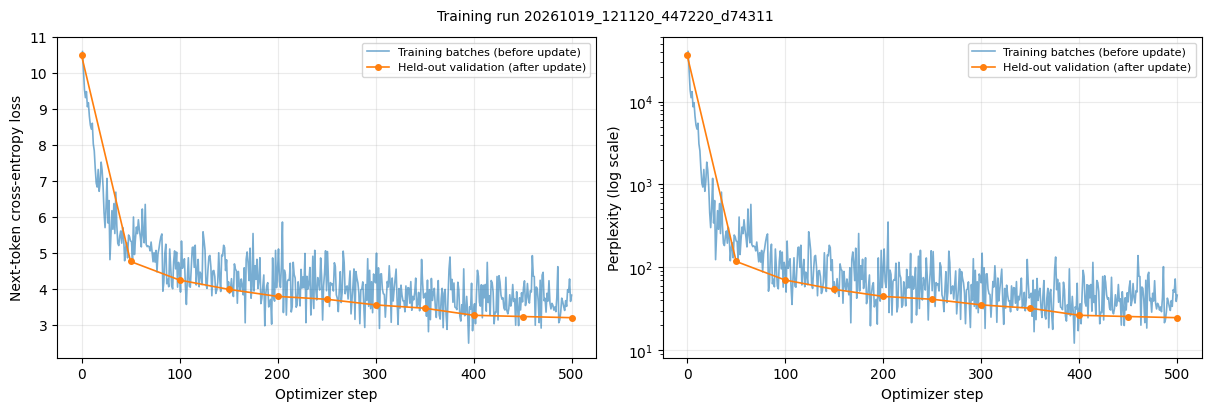

Validation loss: 3.2024; perplexity: 24.59
Report figures: C:\Users\PC CABA DZ\Desktop\SACLABS\NLP_labs_Saclay\Lab5_LM_Transformers\Part1\runs\20261019_121120_447220_d74311\learning_curves.png
{
  "run_id": "20261019_121120_447220_d74311",
  "selected_training_samples": 2000,
  "validation_samples": 32,
  "configured_epochs": 1,
  "epochs_completed": 0.5,
  "steps_completed": 500,
  "samples_processed": 1000,
  "target_tokens_processed": 63000,
  "elapsed_seconds": 109.60260620014742
}


In [32]:
# Recreate these charts later with plot_run(Path("runs/<run folder>")) as well.
figure = plot_run(RUN_DIR)
plt.show()
final_validation = run_metadata["final_validation"]
print(f"Validation loss: {final_validation['loss']:.4f}; "
      f"perplexity: {final_validation['perplexity']:.2f}")
print(f"Report figures: {RUN_DIR / 'learning_curves.png'}")
print(json.dumps({key: run_metadata[key] for key in (
    "run_id", "selected_training_samples", "validation_samples", "configured_epochs",
    "epochs_completed", "steps_completed", "samples_processed", "target_tokens_processed",
    "elapsed_seconds")}, indent=2))


## Choices and conclusion

The architecture uses the requested vocabulary of 32,768, 256-dimensional
embeddings, 512-dimensional feedforward layers, four 64-dimensional attention
heads, and eight pre-RMSNorm decoder blocks with RoPE and SwiGLU.

Each run records its settings, actual steps, sample presentations (including
repeated stories over epochs), effective epochs, target tokens, and validation
metrics. Use the saved curves and generated examples to describe your results.
Training/validation loss may fluctuate; compare runs with identical validation
subsets, tokenizers, and maximum lengths. A short run establishes that the
pipeline works; good story generation requires more training.

The supplied optimizer-only checkpoint is preserved and unused. Each new run
saves both model and optimizer weights in its own timestamped directory.
